# Dataset C: COVID-19 Vaccine Prediction\nThis notebook contains an end-to-end machine learning pipeline for predicting whether individuals took the COVID-19 vaccine based on Dataset C features.

## 1. Upload the Required Dataset Files

In [9]:
from google.colab import files
uploaded = files.upload()

print("\nUploaded files:")
for filename in uploaded:
    print("-", filename)

Saving dataset_C_testing.csv to dataset_C_testing (1).csv

Uploaded files:
- dataset_C_testing (1).csv


In [10]:
from google.colab import files
uploaded = files.upload()

print("\nUploaded files:")
for filename in uploaded:
    print("-", filename)

Saving dataset_C_training.csv to dataset_C_training (1).csv

Uploaded files:
- dataset_C_training (1).csv


In [11]:
from google.colab import files
uploaded = files.upload()

print("\nUploaded files:")
for filename in uploaded:
    print("-", filename)

Saving dataset_C_example_submission.csv to dataset_C_example_submission (1).csv

Uploaded files:
- dataset_C_example_submission (1).csv


## 2. Install and Import Libraries

In [14]:
!pip install -q pandas numpy scikit-learn xgboost matplotlib seaborn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy import stats

# Scikit-Learn Models & Preprocessing
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Evaluation Metrics & Model Selection
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
    auc
)
from sklearn.model_selection import train_test_split

print("All libraries imported successfully!")

# Define dataset column names
TARGET = "covid_vaccine"
ID_COLUMN = "respondent_id"

print("Target column:", TARGET)
print("ID column:", ID_COLUMN)

All libraries imported successfully!
Target column: covid_vaccine
ID column: respondent_id


## 3. Load and Inspect the Datasets

In [15]:
TRAIN_FILE = Path("/content/dataset_C_training.csv")
TEST_FILE = Path("/content/dataset_C_testing.csv")
SAMPLE_FILE = Path("/content/dataset_C_example_submission.csv")

required_files = [TRAIN_FILE, TEST_FILE, SAMPLE_FILE]
missing_files = [p.name for p in required_files if not p.exists()]
if missing_files:
    raise FileNotFoundError(
        "Missing file(s): " + ", ".join(missing_files) +
        ". Run the upload cell above and select the missing CSV file(s)."
    )

train_df = pd.read_csv(TRAIN_FILE)
test_df = pd.read_csv(TEST_FILE)
sample_df = pd.read_csv(SAMPLE_FILE)

print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)
print("Example submission shape:", sample_df.shape)

# Verify columns safely after loading dataframes
print("Training target exists:", TARGET in train_df.columns)
print("Training ID exists:", ID_COLUMN in train_df.columns)
print("Testing ID exists:", ID_COLUMN in test_df.columns)

if TARGET not in train_df.columns:
    raise ValueError(f"The labelled training CSV must contain '{TARGET}'.")
for frame_name, frame in [("training", train_df), ("testing", test_df), ("example submission", sample_df)]:
    if ID_COLUMN not in frame.columns:
        raise ValueError(f"The {frame_name} CSV must contain '{ID_COLUMN}'.")

display(train_df.head())

Training shape: (4756, 31)
Testing shape: (4749, 30)
Example submission shape: (4749, 2)
Training target exists: True
Training ID exists: True
Testing ID exists: True


,respondent_id,covid_concern,covid_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,census_msa,household_adults,household_children,doctor_recc_covid,opinion_covid_vacc_effective,opinion_covid_risk,opinion_covid_sick_from_vacc,employment_sector,number_chronic_med_conditions,covid_vaccine
0,1,3.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,...,"MSA, Principle City",3.0,2.0,0,4,4,2.0,construction,1,0
1,2,2.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,Non-MSA,0.0,0.0,0,5,2,1.0,education,0,1
2,3,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,"MSA, Not Principle City",0.0,0.0,0,2,2,5.0,wholesale,3,0
3,4,2.0,2.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"MSA, Not Principle City",1.0,0.0,1,3,3,2.0,NaN,1,1
4,5,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,"MSA, Not Principle City",0.0,0.0,0,3,2,2.0,wholesale,0,0


## 4. Prepare Features and Exploratory Data Analysis (EDA)

Number of features: 29
Numeric features: 19
Categorical features: 10
Target distribution:


,count
covid_vaccine,
0,3202
1,1554


/tmp/ipykernel_686/2202414873.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=train_df, x=TARGET, palette="Set2")


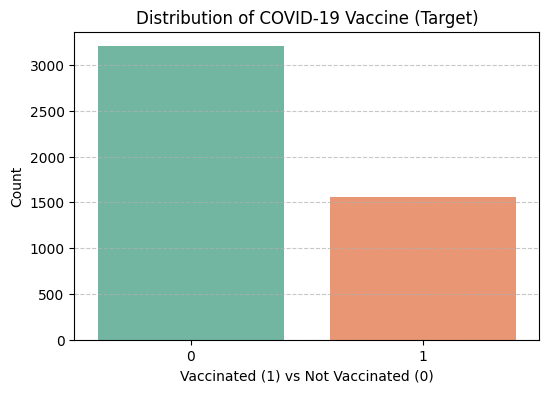


--- ANOVA Feature Correlation Results (Top 10) ---


,Feature,F-Statistic,p-value,Significant (alpha=0.05)
0,doctor_recc_covid,1080.722911,9.304706e-214,Yes
1,opinion_covid_risk,730.432978,8.997150e-150,Yes
2,opinion_covid_vacc_effective,396.039176,1.036007e-84,Yes
3,health_worker,187.010407,9.194702e-42,Yes
4,covid_knowledge,131.077602,5.891010e-30,Yes
5,covid_concern,88.280688,8.601082e-21,Yes
6,health_insurance,79.238442,9.590677e-19,Yes
7,number_chronic_med_conditions,63.695468,1.806049e-15,Yes
8,behavioral_touch_face,45.349343,1.845017e-11,Yes
9,behavioral_wash_hands,27.078086,2.036374e-07,Yes


In [16]:
train_df = train_df.dropna(subset=[TARGET]).copy()
y = train_df[TARGET].astype(int)

feature_columns = [
    col for col in train_df.columns
    if col not in [TARGET, ID_COLUMN] and col in test_df.columns
]
if not feature_columns:
    raise ValueError("No shared feature columns found between training and testing data.")

X = train_df[feature_columns].copy()
X_test = test_df[feature_columns].copy()

numeric_columns = X.select_dtypes(include=["number", "bool"]).columns.tolist()
categorical_columns = [c for c in feature_columns if c not in numeric_columns]

print("Number of features:", len(feature_columns))
print("Numeric features:", len(numeric_columns))
print("Categorical features:", len(categorical_columns))
print("Target distribution:")
display(y.value_counts().sort_index().rename("count").to_frame())

if y.nunique() < 2:
    raise ValueError("The training target must contain at least two classes.")

# 1. Distribution of the Target variable
plt.figure(figsize=(6, 4))
sns.countplot(data=train_df, x=TARGET, palette="Set2")
plt.title("Distribution of COVID-19 Vaccine (Target)")
plt.xlabel("Vaccinated (1) vs Not Vaccinated (0)")
plt.ylabel("Count")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# 2. Statistical significance of numeric features (ANOVA test)
anova_results = []
for col in numeric_columns:
    g0 = train_df[train_df[TARGET] == 0][col].dropna()
    g1 = train_df[train_df[TARGET] == 1][col].dropna()

    if len(g0) > 1 and len(g1) > 1:
        f_stat, p_val = stats.f_oneway(g0, g1)
        anova_results.append({
            "Feature": col,
            "F-Statistic": f_stat,
            "p-value": p_val,
            "Significant (alpha=0.05)": "Yes" if p_val < 0.05 else "No"
        })

anova_df = pd.DataFrame(anova_results).sort_values(by="F-Statistic", ascending=False).reset_index(drop=True)
print("\n--- ANOVA Feature Correlation Results (Top 10) ---")
display(anova_df.head(10))

## 5. Model Building and Validation Split

In [17]:
# Single unified train-validation split (80% train, 20% validation)
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features shape:", X_train.shape)
print("Validation features shape:", X_valid.shape)

# Helper function to build preprocessors
def make_preprocessor(scale_numeric=False):
    numeric_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale_numeric:
        numeric_steps.append(("scaler", StandardScaler()))

    numeric_pipeline = Pipeline(numeric_steps)
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])

    return ColumnTransformer([
        ("numeric", numeric_pipeline, numeric_columns),
        ("categorical", categorical_pipeline, categorical_columns)
    ], remainder="drop")

# Define classification models
models = {
    "Random Forest": Pipeline([
        ("preprocessing", make_preprocessor(False)),
        ("classifier", RandomForestClassifier(n_estimators=200, random_state=42, class_weight="balanced"))
    ]),
    "Extra Trees": Pipeline([
        ("preprocessing", make_preprocessor(False)),
        ("classifier", ExtraTreesClassifier(n_estimators=200, random_state=42, class_weight="balanced"))
    ]),
    "SVM": Pipeline([
        ("preprocessing", make_preprocessor(True)),
        ("classifier", SVC(kernel="rbf", probability=True, class_weight="balanced", random_state=42))
    ]),
    "XGBoost": Pipeline([
        ("preprocessing", make_preprocessor(False)),
        ("classifier", XGBClassifier(n_estimators=200, learning_rate=0.05, max_depth=5, eval_metric="logloss", random_state=42))
    ]),
    "KNN": Pipeline([
        ("preprocessing", make_preprocessor(True)),
        ("classifier", KNeighborsClassifier(n_neighbors=5))
    ])
}

print("Pipelines initialized successfully.")

Training features shape: (3804, 29)
Validation features shape: (952, 29)
Pipelines initialized successfully.


## 6. Train, Evaluate, Select Best Model & Generate Submission

In [18]:
results = []

for name, model in models.items():
    print(f"Training and evaluating: {name}")
    model.fit(X_train, y_train)
    predictions = model.predict(X_valid)
    probabilities = model.predict_proba(X_valid)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_valid, predictions),
        "Precision": precision_score(y_valid, predictions, zero_division=0),
        "Recall": recall_score(y_valid, predictions, zero_division=0),
        "F1-score": f1_score(y_valid, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_valid, probabilities)
    })

results_df = pd.DataFrame(results).sort_values(by="F1-score", ascending=False).reset_index(drop=True)

print("\n--- MODEL PERFORMANCE COMPARISON ---")
display(results_df)

best_model_name = results_df.iloc[0]["Model"]
print(f"\nBest performing model selected: {best_model_name}")

# Retrain best model on ALL available training data
final_model = models[best_model_name]
final_model.fit(X, y)
print("Final model successfully retrained on full training dataset.")

# Generate test predictions
test_predictions = final_model.predict(X_test)

# Create final submission file
submission = sample_df[[ID_COLUMN]].copy()
submission[TARGET] = test_predictions
submission[TARGET] = submission[TARGET].astype(int)

submission_path = "/content/dataset_C_submission.csv"
submission.to_csv(submission_path, index=False)

print("\nSubmission file created successfully!")
display(submission.head())
print(submission[TARGET].value_counts())

Training and evaluating: Random Forest
Training and evaluating: Extra Trees
Training and evaluating: SVM
Training and evaluating: XGBoost
Training and evaluating: KNN

--- MODEL PERFORMANCE COMPARISON ---


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,SVM,0.771008,0.634783,0.704180,0.667683,0.819274
1,XGBoost,0.799370,0.734375,0.604502,0.663139,0.818757
2,Random Forest,0.775210,0.725581,0.501608,0.593156,0.817633
3,Extra Trees,0.767857,0.710280,0.488746,0.579048,0.810505
4,KNN,0.744748,0.642857,0.491961,0.557377,0.750255



Best performing model selected: SVM
Final model successfully retrained on full training dataset.

Submission file created successfully!


,respondent_id,covid_vaccine
0,4757,0
1,4758,0
2,4759,0
3,4760,1
4,4761,0


covid_vaccine
0    2979
1    1770
Name: count, dtype: int64


## 7. Advanced Model Visualizations

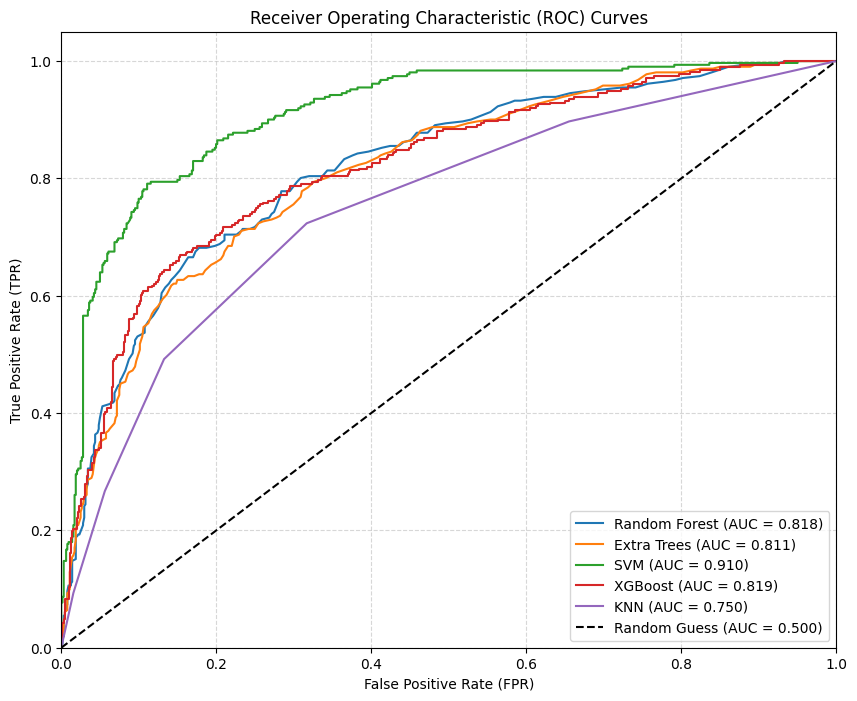

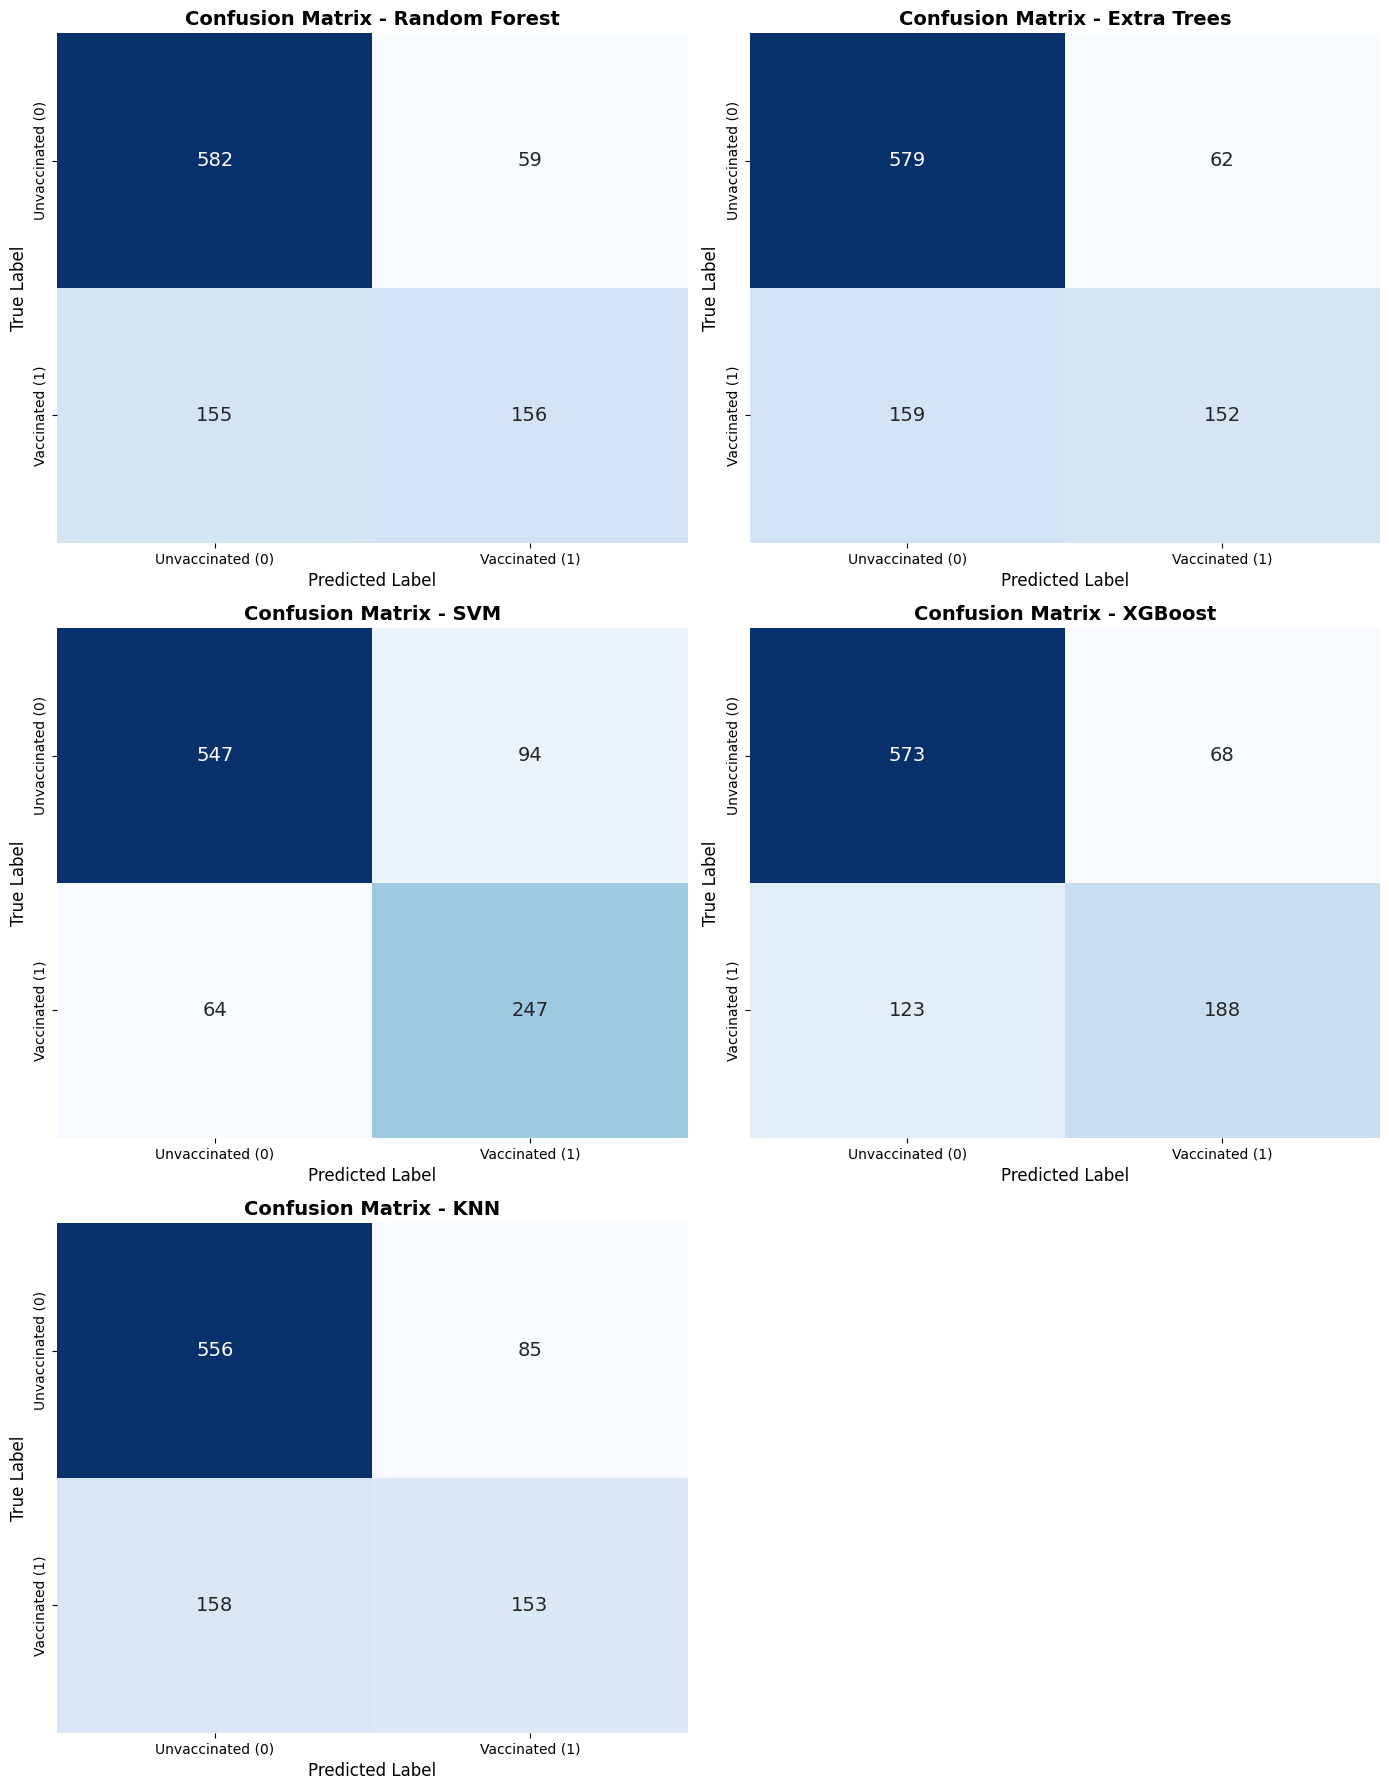

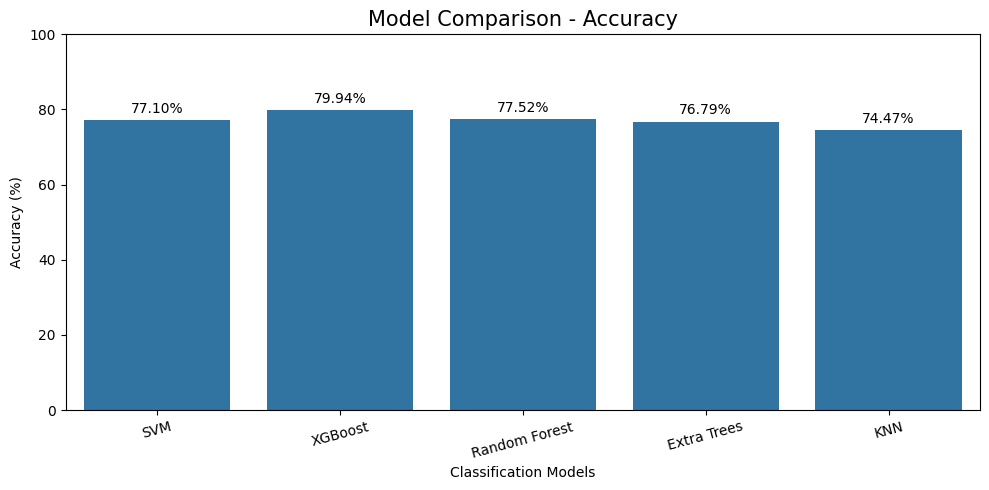

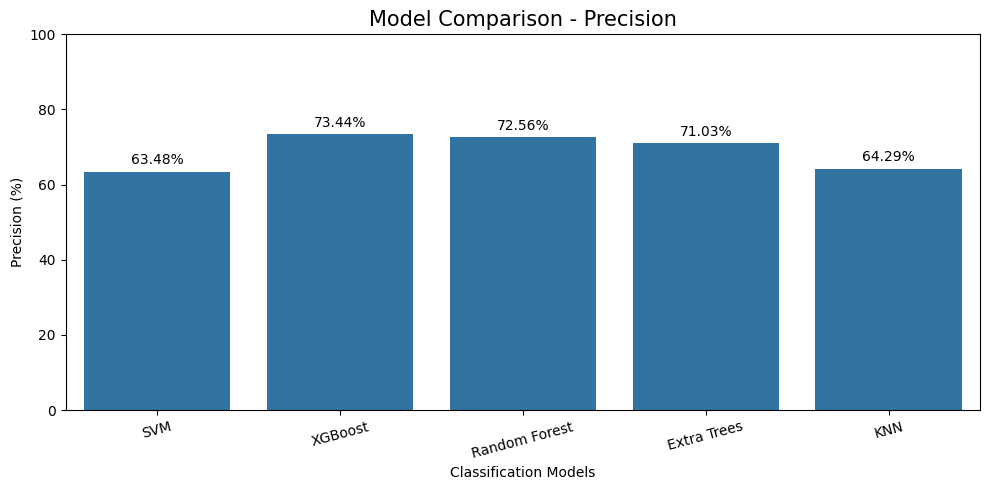

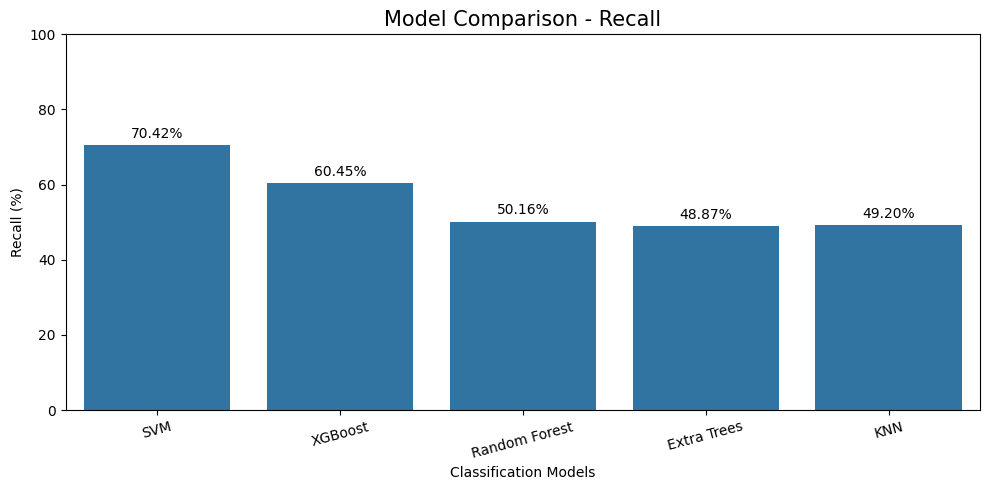

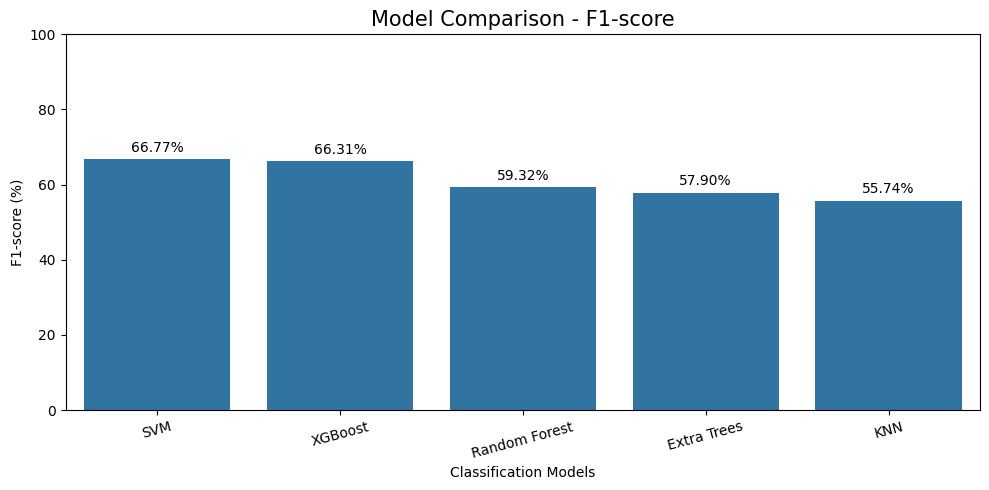

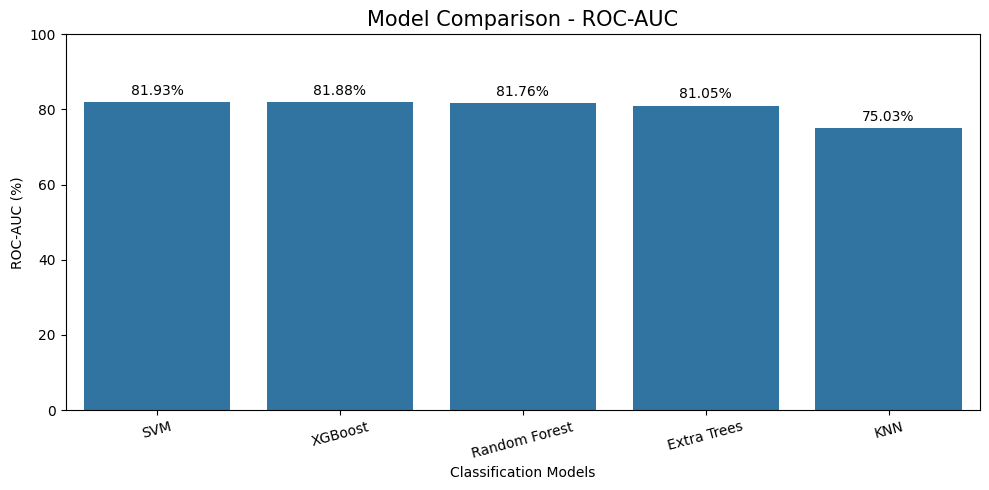

In [19]:
# 1. ROC Curves
plt.figure(figsize=(10, 8))
for name, model in models.items():
    y_probs = model.predict_proba(X_valid)[:, 1]
    fpr, tpr, _ = roc_curve(y_valid, y_probs)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc:.3f})")

plt.plot([0, 1], [0, 1], 'k--', label="Random Guess (AUC = 0.500)")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('Receiver Operating Characteristic (ROC) Curves')
plt.legend(loc="lower right")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# 2. Confusion Matrices Subplot
fig, axes = plt.subplots(3, 2, figsize=(14, 18))
axes = axes.ravel()

for idx, (name, model) in enumerate(models.items()):
    val_preds = model.predict(X_valid)
    cm = confusion_matrix(y_valid, val_preds)

    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", ax=axes[idx], cbar=False, annot_kws={"size": 14}
    )
    axes[idx].set_title(f"Confusion Matrix - {name}", fontsize=14, weight='bold')
    axes[idx].set_xlabel("Predicted Label", fontsize=12)
    axes[idx].set_ylabel("True Label", fontsize=12)
    axes[idx].set_xticklabels(["Unvaccinated (0)", "Vaccinated (1)"])
    axes[idx].set_yticklabels(["Unvaccinated (0)", "Vaccinated (1)"])

fig.delaxes(axes[5])
plt.tight_layout()
plt.show()

# 3. Bar Charts for Metrics
metrics = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]
plot_df = results_df.copy()
plot_df[metrics] = plot_df[metrics] * 100

for metric in metrics:
    plt.figure(figsize=(10, 5))
    ax = sns.barplot(data=plot_df, x="Model", y=metric)
    plt.title(f"Model Comparison - {metric}", fontsize=15)
    plt.xlabel("Classification Models")
    plt.ylabel(f"{metric} (%)")
    plt.ylim(0, 100)
    plt.xticks(rotation=15)

    for container in ax.containers:
        ax.bar_label(container, fmt="%.2f%%", padding=3)

    plt.tight_layout()
    plt.show()

## 8. Download Submission File

In [20]:
from google.colab import files

submission_path = "/content/dataset_C_submission.csv"
files.download(submission_path)
print("Download initiated for submission file.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download initiated for submission file.
